# Models
[Previous Notebook](preprocessing.ipynb) | [**Next Notebook** (TBD)]()

To begin this section, i would like to do some inital analysis of certain models discussed in the course and why they may or may not be a good fit for the problem

## Instance and tree based
### K Nearest Neighbours
As said before, the dataset is very imbalanced (~97% bias towards not depressed). Because of this, I think that voting by neighbourhood majority will not be a very effective means of predicting the target, especially if the individual features have a lot of varience, which i saw evidence of through the `LogisticRegression` tests of the previous notebook (~0.23 `std`).

### Decision Tree
Unlike `KNN`, A `Decision Tree` has the potential to be a very good model for this problem. With a suitible `max_depth` and split criteria, a decision tree can uncover more complex patterns in a dataset and is much more fitted for imbalanced data than KNN.

## Ensembles
### Random Forest
Although `Random Forest` is built on the back of decision trees, I do not see it being an effective model for this problem. By definition, `Random Forest` chooses a random subset of features for each split while constructing the tree for each bootstrap sample and then aggregate by voting. Fro my understanding of the problem and due to the poor balance of the dataset, i dont think aggregation (voting) will be a fair means of resolving a prediction. 

### Gradient Boost
Building on the predicted effectiveness of a `Decision Tree`, I think `Gradient Boost` will be a better ensemble method for increasing model performance, as it incrementally cancels the errors of the model using the samples loss gradient. From my own intuition, keeping in mind the imbalanced dataset and the logic of the problem, incrementally adjusting the error of decisions in the tree makes more sense than randomly choosing features for each split and aggregating the results at the end.

# To begin...
I will allow importing my modular scripts from [src/](/src/) and split my dataset into training and test sets to avoid leakage.

In [78]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import pandas as pd
import numpy as np
import environment

I will then split the data into training and testing sets before modelling to avoid leakage. This will also allow me to use the same splits for all models in this section

In [79]:
from get_data_splits import get_data_splits

splits = get_data_splits()
X_train, X_test, y_train, y_test = splits

print(f"Training set: {y_train.shape[0]}, Test set: {y_test.shape[0]}")
print(f"Random State: {environment.Random_State}")

Training set: 840, Test set: 360
Random State: 42


# KNN

In [98]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from preprocessor import preprocessor
from grid_cross_validation import grid_cross_validation

knn = make_pipeline(preprocessor, StandardScaler(), KNeighborsClassifier())

knn_cv, best_estimator, best_params = grid_cross_validation(knn, X_train, y_train, param_grid={
    'kneighborsclassifier__n_neighbors': [3, 5, 7, 11, 21],
    'kneighborsclassifier__weights': ['uniform', 'distance'],
    'kneighborsclassifier__p': [1, 2, 3]
})

display(best_params)
print("Best f1 score: ", knn_cv.best_score_)

,Best Parameter
n_neighbors,3
p,2
weights,uniform


Best f1 score:  0.08


,predicted not depressed,predicted depressed
actual not depressed,351,0
actual depressed,9,0


Classification Report
               precision    recall  f1-score   support

not depressed       0.97      1.00      0.99       351
    depressed       0.00      0.00      0.00         9

     accuracy                           0.97       360
    macro avg       0.49      0.50      0.49       360
 weighted avg       0.95      0.97      0.96       360



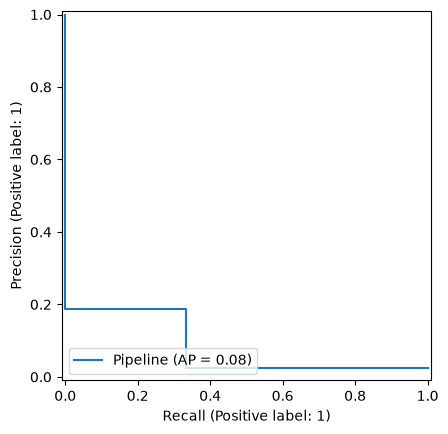

In [ ]:
from run_test import run_test

knn_results = run_test(best_estimator, splits)
display(knn_results['confusion_matrix'])
print(knn_results['classification_report'])

### Interpretation of results

As you can see, `KNN` performs absolutely horribly for my problem, with `0`'s for all positive metrics. This makes sense as the dataset is so imbalanced and the datapoints likely do not lie very close in feature space. Additionally, the added dimensions due to onehot encoding skew the distance values.

# Decision Tree

In [100]:
from sklearn.tree import DecisionTreeClassifier

decisionTree = make_pipeline(preprocessor, DecisionTreeClassifier(criterion='entropy', random_state=environment.Random_State))

decisionTree_cv, best_estimator, best_params = grid_cross_validation(decisionTree, X_train, y_train, param_grid={
    'decisiontreeclassifier__max_depth': [1, 3, 5, 10],
})

display(best_params)
print("Best f1 score: ", decisionTree_cv.best_score_)

,Best Parameter
max_depth,5


Best f1 score:  0.9777777777777779


,predicted not depressed,predicted depressed
actual not depressed,351,0
actual depressed,0,9


Classification Report
               precision    recall  f1-score   support

not depressed       1.00      1.00      1.00       351
    depressed       1.00      1.00      1.00         9

     accuracy                           1.00       360
    macro avg       1.00      1.00      1.00       360
 weighted avg       1.00      1.00      1.00       360



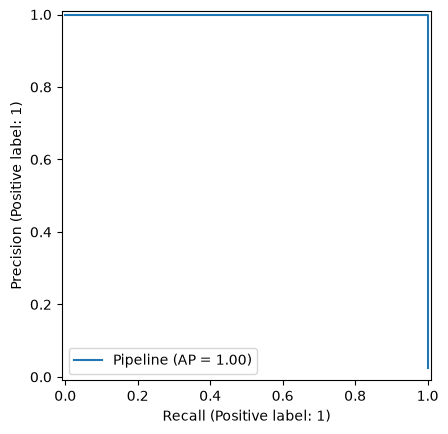

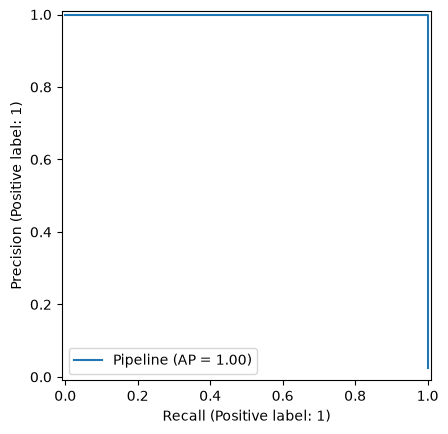

In [ ]:
from run_test import run_test

decision_tree_results = run_test(best_estimator, splits)
display(decision_tree_results['confusion_matrix'])
print(decision_tree_results['classification_report'])

### Interpretation of results
The `Decision Tree` performed exceptionally with `f1_score=0.97` for validation and `f1_score=1.0` for testing. In fact it performed much better than i originally expected. 

# Random Forest

In [104]:
from sklearn.ensemble import RandomForestClassifier

randForest = make_pipeline(preprocessor, RandomForestClassifier(criterion='entropy', n_jobs=-1, random_state=environment.Random_State))

randForest_cv, best_estimator, best_params = grid_cross_validation(randForest, X_train, y_train, param_grid={
    'randomforestclassifier__max_depth': [1, 3, 5, 10, 15, 20],
    'randomforestclassifier__n_estimators': [10, 50, 100],
})

display(best_params)
print("Best f1 score: ", randForest_cv.best_score_)

,Best Parameter
max_depth,10
n_estimators,50


Best f1 score:  0.3066666666666667


,predicted not depressed,predicted depressed
actual not depressed,351,0
actual depressed,8,1


Classification Report
               precision    recall  f1-score   support

not depressed       0.98      1.00      0.99       351
    depressed       1.00      0.11      0.20         9

     accuracy                           0.98       360
    macro avg       0.99      0.56      0.59       360
 weighted avg       0.98      0.98      0.97       360



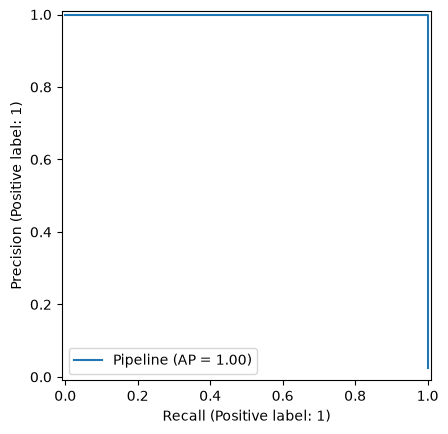

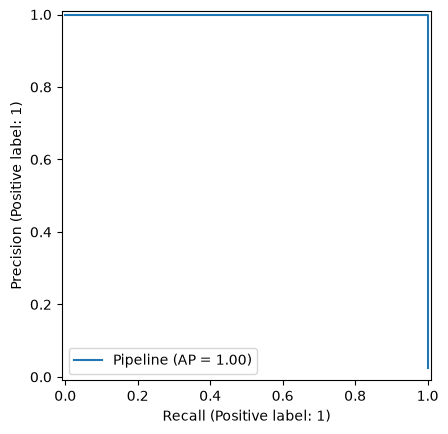

In [ ]:
random_forest_results = run_test(best_estimator, splits)
display(random_forest_results['confusion_matrix'])
print(random_forest_results['classification_report'])

# Gradient Boost

In [86]:
from sklearn.ensemble import GradientBoostingClassifier

GBoost = make_pipeline(preprocessor, GradientBoostingClassifier(random_state=environment.Random_State))

gboost_cv, best_estimator, best_params = grid_cross_validation(GBoost, X_train, y_train, param_grid={
    'gradientboostingclassifier__max_depth': [3, 5, 7, 10],
    'gradientboostingclassifier__n_estimators': [10, 100, 500, 1000],
    'gradientboostingclassifier__learning_rate': [0.01, 0.1, 0.2, 0.5, 1]
})

display(best_params)
print("Best f1 score: ", gboost_cv.best_score_)

,Best Parameter
learning_rate,0.01
max_depth,3.00
n_estimators,1000.00


Best f1 score:  0.9492063492063492


In [87]:
gradient_boosting_results = run_test(best_estimator, splits)
display(gradient_boosting_results['confusion_matrix'])
print(gradient_boosting_results['classification_report'])

,predicted not depressed,predicted depressed
actual not depressed,351,0
actual depressed,0,9


Classification Report
               precision    recall  f1-score   support

not depressed       1.00      1.00      1.00       351
    depressed       1.00      1.00      1.00         9

     accuracy                           1.00       360
    macro avg       1.00      1.00      1.00       360
 weighted avg       1.00      1.00      1.00       360



# To conclude this section...


In [96]:
from baseline_model import baseline_model

baseline_cv, best_estimator, best_params = grid_cross_validation(baseline_model, X_train, y_train, param_grid={})
baseline_score = run_test(baseline_model.fit(X_train, y_train), splits)["f1_score"]

df = pd.DataFrame([
  ("KNN", knn_cv.best_score_, knn_results['f1_score']),
  ("Random Forest", randForest_cv.best_score_, random_forest_results['f1_score']),
  ("Linear Regression", baseline_cv.best_score_, baseline_score),
  ("Gradient Boosting", gboost_cv.best_score_, gradient_boosting_results['f1_score']),
  ("Decision Tree", decisionTree_cv.best_score_, decision_tree_results['f1_score']),
], columns=['Model', 'Best F1 Score (CV)', 'F1 Score (Test)'])

display(df)

,Model,Best F1 Score (CV),F1 Score (Test)
0,KNN,0.080000,0.000000
1,Random Forest,0.306667,0.200000
2,Linear Regression,0.710000,0.571429
3,Gradient Boosting,0.949206,1.000000
4,Decision Tree,0.977778,1.000000
